# Phase 2: AI Collision Risk Prediction (Gradient Boosting)

Real ESA conjunction warnings (Kelvins Collision Avoidance Challenge). Run all cells: the first one downloads the data from ESA (~120 MB, about a minute).

### 0. Download the ESA data

In [1]:
import os, urllib.request, zipfile
base = "https://kelvins.esa.int/media/public/competitions/collision-avoidance-challenge/"
if not os.path.exists("train_data.csv"):
    urllib.request.urlretrieve(base + "train_data.zip", "train_data.zip")
    zipfile.ZipFile("train_data.zip").extractall(".")
if not os.path.exists("test_data.csv"):
    urllib.request.urlretrieve(base + "test_data.csv", "test_data.csv")
print("Data ready")

Data ready


### 1. Load the data

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, fbeta_score

features = ["time_to_tca", "risk", "miss_distance",
            "relative_speed", "max_risk_estimate", "mahalanobis_distance"]

train = pd.read_csv("train_data.csv", usecols=["event_id"] + features)
test = pd.read_csv("test_data.csv", usecols=["event_id"] + features)
print("Training rows:", len(train), "| Test rows:", len(test))

Training rows: 162634 | Test rows: 24484


### 2. Build one example per event
**Input:** the latest warning at least 2 days before closest approach.  
**Answer:** whether the final warning is high risk (collision probability ≥ 1 in a million).

In [3]:
early = train[train["time_to_tca"] >= 2]
early = early.loc[early.groupby("event_id")["time_to_tca"].idxmin()]

final = train.loc[train.groupby("event_id")["time_to_tca"].idxmin(), ["event_id", "risk", "time_to_tca"]]
final = final.rename(columns={"risk": "final_risk", "time_to_tca": "final_days"})

data = early.merge(final, on="event_id")
data = data[data["final_days"] < 1].copy()
data["high_risk"] = (data["final_risk"] >= -6).astype(int)
print("Events:", len(data), "| High risk:", data["high_risk"].sum())

Events: 8293 | High risk: 66


### 3. Train Gradient Boosting
Trees are built one after another; each new tree corrects the errors of the previous ones. `class_weight="balanced"` stops the model from ignoring the rare high-risk events.

In [4]:
X, y = data[features], data["high_risk"]

X_train, X_other, y_train, y_other = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_valid, X_check, y_valid, y_check = train_test_split(X_other, y_other, test_size=0.5,
                                                      stratify=y_other, random_state=42)

model = HistGradientBoostingClassifier(max_iter=300, max_depth=3, learning_rate=0.05,
                                       class_weight="balanced", random_state=42)
model.fit(X_train, y_train)
print("Model trained")

Model trained


### 4. Compare with doing nothing
**Do nothing** = assume the risk 2 days out will not change, and raise an alert if it is already ≥ 1e-6. The AI is only useful if it beats this.  
We score with **recall** (share of dangerous events caught) and **F2**, which weights recall above precision because a missed collision costs far more than a false alarm.

In [5]:
# Alert cutoff chosen on validation events only
valid_scores = model.predict_proba(X_valid)[:, 1]
cutoff = max([0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5],
             key=lambda t: fbeta_score(y_valid, valid_scores >= t, beta=2, zero_division=0))

results = {
    "Do nothing (trust early risk)": X_check["risk"] >= -6,
    "Gradient Boosting": model.predict_proba(X_check)[:, 1] >= cutoff,
}
print(f"Check set: {len(y_check)} events, {y_check.sum()} high risk | alert cutoff = {cutoff}\n")
print(pd.DataFrame({name: {
    "Precision": precision_score(y_check, r, zero_division=0),
    "Recall": recall_score(y_check, r, zero_division=0),
    "F2 score": fbeta_score(y_check, r, beta=2, zero_division=0),
    "Alerts raised": int(r.sum()),
} for name, r in results.items()}).T.round(3))

Check set: 1659 events, 13 high risk | alert cutoff = 0.1

                               Precision  Recall  F2 score  Alerts raised
Do nothing (trust early risk)      0.129   0.615     0.351           62.0
Gradient Boosting                  0.117   0.692     0.349           77.0


### 5. Predict the test events

In [6]:
model.fit(X, y)  # retrain on all labelled events

new = test[test["time_to_tca"] >= 2]
new = new.loc[new.groupby("event_id")["time_to_tca"].idxmin()]
scores = model.predict_proba(new[features])[:, 1]

predictions = pd.DataFrame({
    "event_id": new["event_id"].to_numpy(),
    "days_before_approach": new["time_to_tca"].round(2).to_numpy(),
    "ai_score": scores.round(3),
    "alert": ["HIGH" if s >= cutoff else "MEDIUM" if s >= cutoff / 2 else "LOW" for s in scores],
})
print(predictions["alert"].value_counts().to_string())

alert
LOW       1847
HIGH       269
MEDIUM      51


### 6. Live demo: change the event ID

 event_id  days_before_approach  ai_score alert
     1767                  2.09     0.995  HIGH


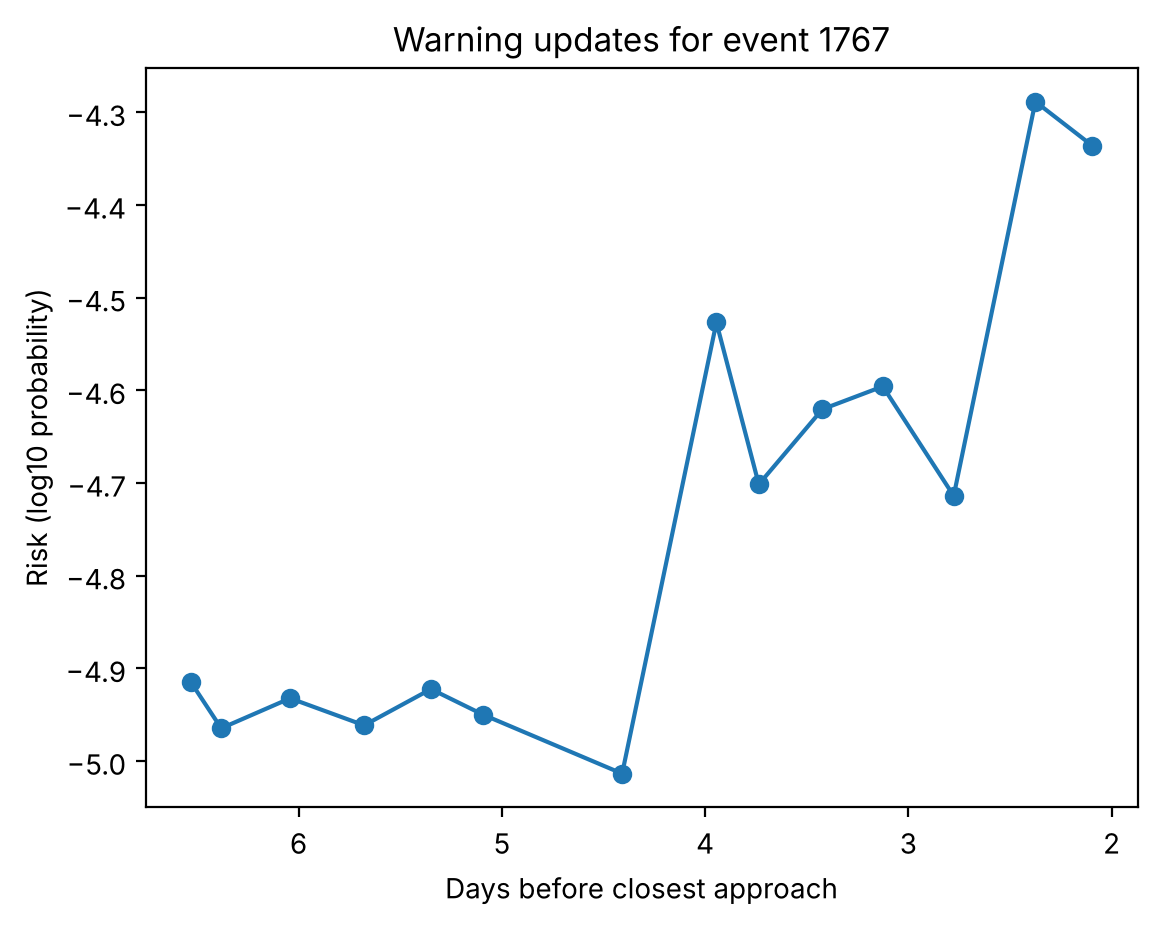

In [7]:
event_id = int(predictions.sort_values("ai_score").iloc[-1]["event_id"])  # or type any ID
print(predictions[predictions["event_id"] == event_id].to_string(index=False))

test[test["event_id"] == event_id].sort_values("time_to_tca").plot(
    x="time_to_tca", y="risk", marker="o", legend=False, xlabel="Days before closest approach",
    ylabel="Risk (log10 probability)", title=f"Warning updates for event {event_id}").invert_xaxis()